# Auction Design for Mass Privatization: the simulation

This notebook builds an artificial economy and runs the design on it, one part at a time. Each part reads the columns made before it and adds its own to the people and firms tables. The last cell saves the run: four files in `runs/run_XX/`, rewritten on every run.

**Order of the parts**
1. Define population and firms in the world: people, points, firms, who works where
2. Round 1: the cash auction
3. The payout and the value of a point
4. The round 3 draws: who is active and which firms each person knows
5. Round 2: the worker auction
6. Round 3: the public auction and the settlement of the exchange


#### Setup

- **Imports:** the functions of each part, from `sim/`. Autoreload picks up edits to the `.py` files without restarting the kernel.
- **Parameters:** every setting of the run in one dict, `params`. Each comment gives the paper's symbol.
- **Run folder:** `run_number` names the folder (`runs/run_01`) and starts every file name (`1_`).

**Randomness.** One seed makes four independent streams: world, round1, round2, round3. Each part draws only from its own stream, so changing one part never moves another part's numbers. A sigma only scales draws that are already made, so changing a sigma never shifts a random draw.

In [1]:
# Reload sim/ on every run, so edits to the .py files show up without restarting the kernel
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sim.world import (draw_world, make_people, make_points, count_insiders, make_firms, make_headcounts,
                       make_book_values, assign_workers, is_insider, worker_points, summarize_points)
from sim.cash_auction import (draw_cash_auction, make_reserves, make_bids, top_values, make_cash_paid,
                              make_first_prices)
from sim.payout import check_split, split_cash, make_payout_per_point, make_payouts, make_point_value
from sim.files import save_run

In [2]:
# Parameters of this run; each comment gives the paper's symbol where there is one
params = {
    "seed": 42,                  # one seed makes every random number of the run
    # part 1, the world
    "n_people": 100_000,         # number of people (the paper's N)
    "sigma_points": 0.5,         # spread of points across people, the sd of log points (the paper's sigma)
    "n_firms": 20,               # number of firms in the pool (the paper's |J|)
    "insider_share": 0.2,        # share of people who work in a firm of the pool (N_W / N)
    "sigma_headcount": 0.8,      # spread of headcounts across firms (the paper's sigma_L)
    "min_headcount": 100,        # smallest headcount, the size test of Section 2 (the paper's L_min)
    "avg_book_per_worker": 100,  # average book value per worker; only sets the unit of money (the paper's kappa)
    "sigma_book": 0.3,           # spread of book value per worker across firms (the paper's sigma_K)
    # the split of every firm, adding up to one
    "cash_block": 0.30,          # share of every firm sold for cash to one investor in round 1 (the paper's a)
    "worker_block": 0.25,        # share sold to the firm's own workers for points in round 2 (the paper's w)
    "public_block": 0.25,        # share sold to all other citizens for points in round 3 (the paper's c)
    "fund_block": 0.20,          # share the fund holds back and sells for cash over the years (the paper's s)
    # round 1, the cash auction
    "min_investors": 2,          # fewest investors bidding for a cash block
    "avg_investors": 4,          # average number of investors per cash block (the paper's g)
    "sigma_investor": 0.5,       # spread of investors' values: how much they disagree (the paper's sigma_v)
    # the payout after round 1
    "payout_share": 0.75,        # share of round 1 cash paid out to citizens; the rest is tax (the paper's lambda_C)
}

In [3]:
# run_number: which run this is; it names the folder and starts every file name
run_number = 1
# run: the folder for this run's files, runs/run_01 for run 1; running again overwrites them
run = Path(f"runs/run_{run_number:02d}")
run.mkdir(parents=True, exist_ok=True)
# prefix: the start of every file name in this run, 1_ for run 1
prefix = f"{run_number}_"

## Define population and firms in the world

**What it makes.** $N$ people, each holding points; $J$ firms in the pool, each with a headcount and a book value; and who works where. Nothing here depends on any auction.

**Draws (world stream, in this order).** First $Z_i$ for every person, then $Z^L_j$ for every firm, then $Z^K_j$ for every firm, all $\mathcal{N}(0,1)$; then one random shuffle of the $N$ people.

**Points.** Lognormal with mean one, so the average person holds one point:

$$
B_i = \exp\left(\sigma Z_i - \tfrac{\sigma^2}{2}\right), \qquad V = \sum_i B_i \approx N .
$$

**Headcounts.** A raw size per firm, scaled so the headcounts add up to the $N_W$ insiders and never fall below $L_{\min}$; the largest firm takes the rounding difference:

$$
\tilde L_j = \exp\left(\sigma_L Z^L_j\right), \qquad L_j = \max\left\{L_{\min},\ \mathrm{round}\left(N_W \frac{\tilde L_j}{\sum_k \tilde L_k}\right)\right\} .
$$

**Book values.** Headcount times a capital per worker that averages $\kappa$:

$$
K_j = \kappa\, L_j \exp\left(\sigma_K Z^K_j - \tfrac{\sigma_K^2}{2}\right) .
$$

**Who works where.** $N_W$ is the insider share of all $N$ people, rounded. The first $L_1$ people of the shuffle work in firm 1, the next $L_2$ in firm 2, and so on; everyone else is an outsider. The shuffle ignores points, so each firm's workers hold about as many points as the firm has workers:

$$
V^W_j = \sum_{i \in W_j} B_i, \qquad \mathbb{E}\left[V^W_j\right] = L_j, \qquad \mathrm{sd}\left[V^W_j\right] = \sqrt{L_j\left(e^{\sigma^2} - 1\right)} .
$$

**Adds.** People: points, firm_id, insider. Firms: headcount, book_value, worker_points.

**In the code.** $N$ `n_people`, $J$ `n_firms`, $\sigma$ `sigma_points`, $Z_i$ `z_points`, $B_i$ `points`, $V$ `total_points`, $N_W$ `n_insiders`, $\sigma_L$ `sigma_headcount`, $Z^L_j$ `z_headcount`, $L_{\min}$ `min_headcount`, $L_j$ `headcount`, $\kappa$ `avg_book_per_worker`, $\sigma_K$ `sigma_book`, $Z^K_j$ `z_book`, $K_j$ `book_value`, the shuffle `shuffle`, $V^W_j$ `worker_points`. `firm_id` 0 means no firm; `insider` is 1 or 0.

#### People and points
Draw the world, start the people table, give everyone points and add them up.

In [4]:
# world_draws: every random number of part 1, from the world stream
world_draws = draw_world(params["seed"], params["n_people"], params["n_firms"])

# people: the people table, one row per person
people = make_people(params["n_people"])

# points: points of each person, a lognormal with mean one
people["points"] = make_points(world_draws["z_points"], params["sigma_points"])

# total_points: all points in the economy, about n_people since the average person holds one point
total_points = people["points"].sum()
print(f"total_points = {total_points:,.4f}")
people

total_points = 99,907.9243


,person_id,points
0,1,1.087808
1,2,1.194572
2,3,0.895291
3,4,0.513183
4,5,1.835121
...,...,...
99995,99996,0.871341
99996,99997,0.278893
99997,99998,1.261879
99998,99999,1.476408


#### Firms: headcounts, book values and who works where
How many insiders there are, then each firm's headcount and book value.

In [5]:
# n_insiders: number of insiders, the given share of all people
n_insiders = count_insiders(params["n_people"], params["insider_share"])
print(f"n_insiders = {n_insiders:,}")

# firms: the firms table, one row per firm
firms = make_firms(params["n_firms"])

# headcount: workers of each firm, at least min_headcount and adding up to n_insiders
firms["headcount"] = make_headcounts(world_draws["z_headcount"], params["sigma_headcount"], n_insiders,
                                     params["min_headcount"])

# book_value: book value of each firm, what its assets would fetch if sold off
firms["book_value"] = make_book_values(world_draws["z_book"], firms["headcount"].to_numpy(),
                                       params["avg_book_per_worker"], params["sigma_book"])
# firm_id: the firm each person works in, 0 for no firm
people["firm_id"] = assign_workers(world_draws["shuffle"], firms["headcount"].to_numpy(), params["n_people"])

# insider: 1 for a person who works in a firm of the pool, 0 for everyone else
people["insider"] = is_insider(people["firm_id"].to_numpy())

# worker_points: points held by the workers of each firm together
firms["worker_points"] = worker_points(people["points"].to_numpy(), people["firm_id"].to_numpy(), params["n_firms"])

firms

n_insiders = 20,000


,firm_id,headcount,book_value,worker_points
0,1,945,110739.635970,947.423826
1,2,1578,166875.756050,1567.513493
2,3,328,20858.394988,322.060290
3,4,280,30374.883206,281.318287
4,5,158,20262.656023,151.391854
5,6,719,72088.578523,706.350284
6,7,881,70778.304825,865.405434
7,8,171,13127.377123,169.482497
8,9,369,24638.482556,369.377304
9,10,266,27406.248805,240.308484


In [6]:
# points_summary: count, min, max, mean, median and std of points for everyone, all insiders and each firm
points_summary = summarize_points(people["points"].to_numpy(), people["firm_id"].to_numpy(), params["n_firms"])
display(points_summary.round(4).head(12))

,count,min,max,mean,median,std
everyone,100000,0.1027,7.5329,0.9991,0.8816,0.5312
insiders,20000,0.1280,5.7793,0.9948,0.8805,0.5228
firm 1,945,0.1348,4.9055,1.0026,0.8807,0.5567
firm 2,1578,0.1445,4.4838,0.9934,0.8824,0.5145
firm 3,328,0.2022,3.7514,0.9819,0.8710,0.5319
firm 4,280,0.2079,2.8346,1.0047,0.8743,0.5048
firm 5,158,0.2982,3.4382,0.9582,0.8443,0.5008
firm 6,719,0.2115,4.4208,0.9824,0.8768,0.4883
firm 7,881,0.1682,3.3456,0.9823,0.8800,0.5043
firm 8,171,0.1511,2.5470,0.9911,0.8992,0.4780


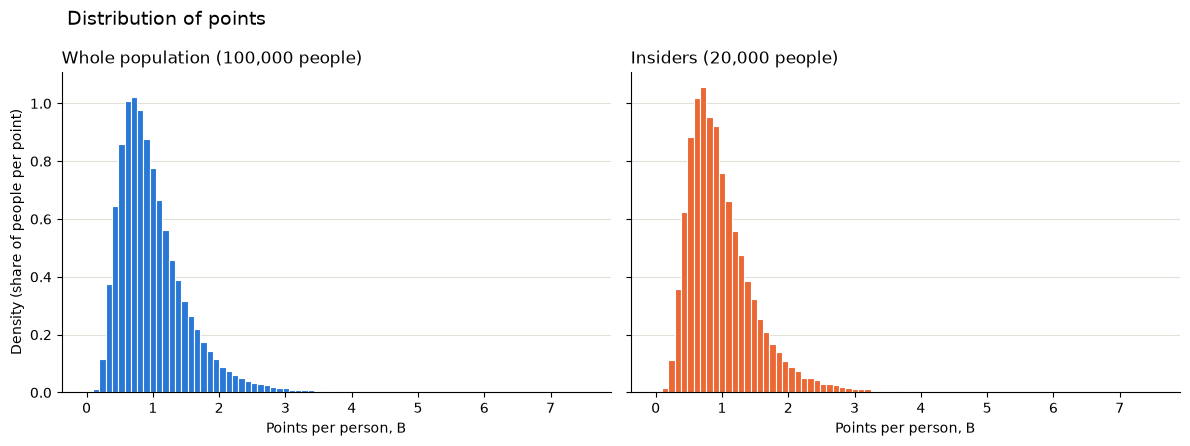

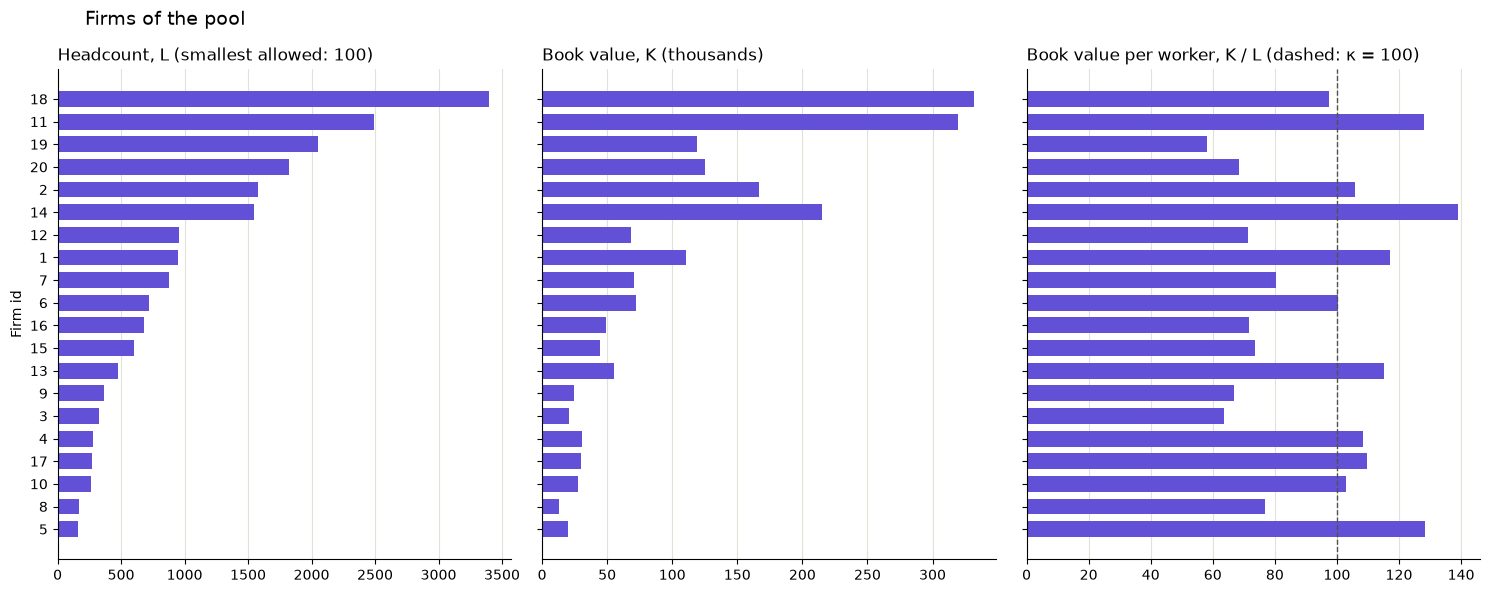

In [7]:
# bins: the same 80 bins for both charts, from 0 to the largest holding
bins = np.linspace(0, people["points"].max(), 80)
# insiders: True for each person who works in a firm of the pool
insiders = people["insider"] == 1

# Two charts side by side, sharing both axes so they compare directly
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)

# Left: the whole population
left.hist(people["points"], bins=bins, density=True, color="#2a78d6", edgecolor="white", linewidth=0.8)
left.set_title(f"Whole population ({len(people):,} people)", loc="left")
left.set_ylabel("Density (share of people per point)")

# Right: the insiders only
right.hist(people.loc[insiders, "points"], bins=bins, density=True, color="#eb6834", edgecolor="white", linewidth=0.8)
right.set_title(f"Insiders ({insiders.sum():,} people)", loc="left")

# Same look for both charts
for ax in (left, right):
    ax.set_xlabel("Points per person, B")
    ax.grid(axis="y", color="#e1e0d9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Distribution of points", x=0.06, ha="left", fontsize=14)
fig.tight_layout()
plt.show()

# ranked: the firms sorted by headcount, largest first, so all three charts list them the same way
ranked = firms.sort_values("headcount", ascending=False)
# labels: the firm ids in that order, for the shared axis
labels = ranked["firm_id"].astype(str)
# book_per_worker: book value per worker of each firm, book_value / headcount
book_per_worker = ranked["book_value"] / ranked["headcount"]

# Three charts side by side, one bar per firm, sharing the list of firms
fig, (left, middle, right) = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

# Left: headcount
left.barh(labels, ranked["headcount"], height=0.7, color="#6250d6")
left.set_title(f"Headcount, L (smallest allowed: {params['min_headcount']})", loc="left")
left.set_ylabel("Firm id")

# Middle: book value, in thousands
middle.barh(labels, ranked["book_value"] / 1000, height=0.7, color="#6250d6")
middle.set_title("Book value, K (thousands)", loc="left")

# Right: book value per worker, with its expected value avg_book_per_worker as a dashed line
right.barh(labels, book_per_worker, height=0.7, color="#6250d6")
right.axvline(params["avg_book_per_worker"], color="#52514e", linestyle="--", linewidth=1)
right.set_title(f"Book value per worker, K / L (dashed: κ = {params['avg_book_per_worker']})", loc="left")

# Same look for all three charts, with the largest firm on top
left.invert_yaxis()
for ax in (left, middle, right):
    ax.grid(axis="x", color="#e1e0d9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Firms of the pool", x=0.06, ha="left", fontsize=14)
fig.tight_layout()
plt.show()

### Auction Round 1: the cash auction

**How it runs.** One English auction per firm, all at the same time. The price of the block opens at the reserve $aK_j$, the block's share of book value, and rises. An investor may leave at any moment, for good, and sees only the price and how many are still in. The last investor left wins. The firm's officers and directors may not bid for it.

**Values (generated).** Firm $j$ draws $n_j$ investors: $\underline{n}$ for sure, then one more with chance $1 - p$ each time until the first no-show, so $\bar{n}$ on average. Investor $b$ values the block at $v_b$, never below the reserve, because the assets can always be sold:

$$
\Pr(n_j = k) = p\,(1 - p)^{k - \underline{n}}, \quad k \ge \underline{n}, \quad p = \frac{1}{\bar{n} - \underline{n} + 1}, \qquad v_b = aK_j \exp\left(\sigma_v |Z_b|\right), \quad Z_b \sim \mathcal{N}(0,1).
$$

**How they bid.** Each investor stays in until the price reaches their own value $v_b$, then leaves: their exit price, in effect their bid, is exactly $v_b$. This is a dominant strategy: a plan that is at least as good as any other, whatever the rivals do and however many there are. Leaving earlier can only lose a block that was worth more than its price; staying longer can only win it at a price above its value. So every investor bids their true value, the highest value wins, and the winner pays the second-highest value. No clock needs simulating: sorting the values gives every exit price.

**Pays, gets, price.** With the values sorted, $v_{(1)} \ge v_{(2)} \ge \dots$, the winner gets the whole block $a$ and pays the price at which the last rival left; a lone investor, and so the first case, is possible only when $\underline{n} = 1$:

$$
P_j = \begin{cases} aK_j & \text{if } n_j = 1 \\ v_{(2)} & \text{if } n_j \ge 2 \end{cases}
\qquad\qquad
p^0_j = \frac{P_j}{a} \quad \text{the first price, per share.}
$$

The first price is what the whole firm is worth at the price the investor paid. It is never revised, and every later price is tied to it.

**In the code.** $a$ `cash_block`, $K_j$ `book_value`, $aK_j$ `reserve`, $n_j$ `n_investors`, $\underline{n}$ `min_investors`, $\bar{n}$ `avg_investors`, $\sigma_v$ `sigma_investor`, $Z_b$ `z_values`, $v_b$ `value`, $v_{(1)}$ `top_value`, $P_j$ `cash_paid`, $p^0_j$ `first_price`.

#### Draws and reserves
How many investors bid for each firm, and each cash block's reserve.

In [8]:
# auction_draws: every random number of round 1, from the round1 stream
auction_draws = draw_cash_auction(params["seed"], params["n_firms"], params["min_investors"], params["avg_investors"])

# n_investors: how many investors bid for each firm's cash block
firms["n_investors"] = auction_draws["n_investors"]

# reserve: the lowest price of each cash block, its share of book value
firms["reserve"] = make_reserves(firms["book_value"].to_numpy(), params["cash_block"])

print(f"{firms['n_investors'].sum()} investors in all, {firms['n_investors'].mean():.2f} per firm")

76 investors in all, 3.80 per firm


#### Bids
Every investor's value for the block, ranked within its firm.

In [9]:
# bids: one row per investor, with its firm, its number in that firm, its value for the block and its rank there
bids = make_bids(firms["n_investors"].to_numpy(), auction_draws["z_values"], firms["reserve"].to_numpy(),
                 params["sigma_investor"])

display(bids.head(10))

,firm_id,investor,value,rank
0,1,1,46664.343415,3
1,1,2,58160.955539,2
2,1,3,61720.610025,1
3,2,1,72666.146887,1
4,2,2,70113.101523,2
5,3,1,13884.493404,2
6,3,2,9125.744548,4
7,3,3,10370.602826,3
8,3,4,18220.343569,1
9,4,1,13099.935987,2


#### Winners and prices
The winner's value, the cash paid (the runner-up's value) and the first price of every firm, plus the round 1 totals and a summary table.

In [10]:
# top_value: the winner's value for each firm's cash block
firms["top_value"] = top_values(bids, params["n_firms"])

# cash_paid: what each winner pays, the runner-up's value
firms["cash_paid"] = make_cash_paid(bids, firms["reserve"].to_numpy())

# first_price: what the whole firm is worth at the price paid for its cash block
firms["first_price"] = make_first_prices(firms["cash_paid"].to_numpy(), params["cash_block"])

# total_cash_paid: all cash paid in round 1, the cash the payout will split
total_cash_paid = firms["cash_paid"].sum()
print(f"total_cash_paid = {total_cash_paid:,.4f}")

# total_first_price: every firm at its first price, the base for the value of a point
total_first_price = firms["first_price"].sum()
print(f"total_first_price = {total_first_price:,.4f}")

# firm_view: each firm's size and round 1 results, plus two columns to read them by
firm_view = firms[["headcount", "book_value", "n_investors", "reserve", "top_value", "cash_paid", "first_price"]].copy()
# price_over_book: first price over book value, the runner-up's multiple of the reserve
firm_view["price_over_book"] = firm_view["first_price"] / firm_view["book_value"]
# winner_gain: what the winner keeps, its value for the block minus what it paid
firm_view["winner_gain"] = firm_view["top_value"] - firm_view["cash_paid"]

# round1_stats: the middle, the range and the all-firms total of every column
round1_stats = firm_view.agg(["median", "mean", "min", "max", "sum"]).T.rename(columns={"sum": "all firms"})
# A sum of ratios means nothing, so for price_over_book "all firms" is total first price over total book value
round1_stats.loc["price_over_book", "all firms"] = total_first_price / firms["book_value"].sum()

display(firms.head(5))
display(round1_stats.style.format("{:,.2f}"))

total_cash_paid = 938,528.1759
total_first_price = 3,128,427.2531


,firm_id,headcount,book_value,worker_points,n_investors,reserve,top_value,cash_paid,first_price
0,1,945,110739.635970,947.423826,3,33221.890791,61720.610025,58160.955539,193869.851797
1,2,1578,166875.756050,1567.513493,2,50062.726815,72666.146887,70113.101523,233710.338408
2,3,328,20858.394988,322.060290,4,6257.518497,18220.343569,13884.493404,46281.644682
3,4,280,30374.883206,281.318287,2,9112.464962,16933.299666,13099.935987,43666.453291
4,5,158,20262.656023,151.391854,11,6078.796807,12769.465706,12256.324274,40854.414245


,median,mean,min,max,all firms
headcount,701.00,"1,000.00",158.00,"3,401.00","20,000.00"
book_value,"61,696.22","95,700.38","13,127.38","331,804.43","1,914,007.64"
n_investors,3.00,3.80,2.00,11.00,76.00
reserve,"18,508.87","28,710.11","3,938.21","99,541.33","574,202.29"
top_value,"37,654.55","65,938.00","9,911.49","250,239.06","1,318,759.98"
cash_paid,"25,150.90","46,926.41","4,623.41","147,164.51","938,528.18"
first_price,"83,836.33","156,421.36","15,411.38","490,548.35","3,128,427.25"
price_over_book,1.51,1.66,1.09,2.34,1.63
winner_gain,"4,811.96","19,011.59",421.78,"109,742.15","380,231.80"


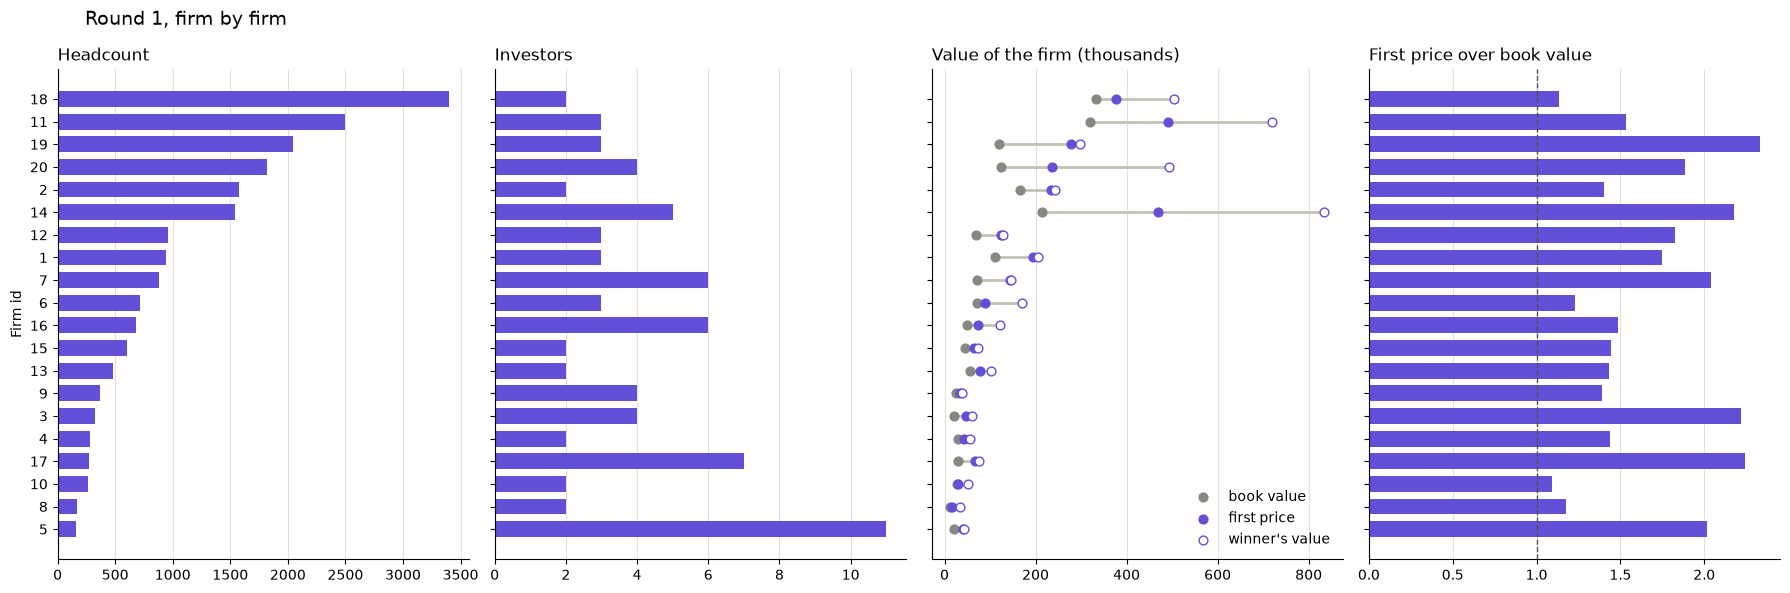

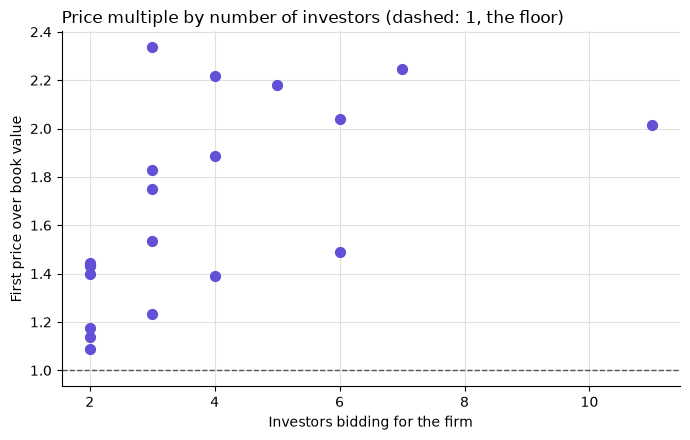

In [11]:
# ranked: the firms sorted by headcount, largest first, the same order as the firm charts above
ranked = firms.sort_values("headcount", ascending=False)
# labels: the firm ids in that order, for the shared axis
labels = ranked["firm_id"].astype(str)
# winner_value: the whole firm at the winner's own value for the block
winner_value = ranked["top_value"] / params["cash_block"]
# price_over_book: first price over book value, the runner-up's multiple of the reserve
price_over_book = ranked["first_price"] / ranked["book_value"]

# Four charts side by side, one row per firm, sharing the list of firms
fig, (size, crowd, worth, multiple) = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

# Headcount of each firm
size.barh(labels, ranked["headcount"], height=0.7, color="#6250d6")
size.set_title("Headcount", loc="left")
size.set_ylabel("Firm id")

# Investors bidding for each firm's cash block
crowd.barh(labels, ranked["n_investors"], height=0.7, color="#6250d6")
crowd.set_title("Investors", loc="left")

# Three values of the whole firm, in thousands: the floor, the price paid and the winner's own value
worth.hlines(labels, ranked["book_value"] / 1000, winner_value / 1000, color="#c3c2b7", linewidth=2)
worth.scatter(ranked["book_value"] / 1000, labels, s=40, color="#898781", zorder=3, label="book value")
worth.scatter(ranked["first_price"] / 1000, labels, s=40, color="#6250d6", zorder=3, label="first price")
worth.scatter(winner_value / 1000, labels, s=40, facecolors="white", edgecolors="#6250d6", zorder=3,
              label="winner's value")
worth.set_title("Value of the firm (thousands)", loc="left")
worth.legend(frameon=False, loc="lower right")

# First price over book value, with 1, the floor, as a dashed line
multiple.barh(labels, price_over_book, height=0.7, color="#6250d6")
multiple.axvline(1, color="#52514e", linestyle="--", linewidth=1)
multiple.set_title("First price over book value", loc="left")

# Same look for all four charts, with the largest firm on top
size.invert_yaxis()
for ax in (size, crowd, worth, multiple):
    ax.grid(axis="x", color="#e1e0d9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Round 1, firm by firm", x=0.05, ha="left", fontsize=14)
fig.tight_layout()
plt.show()

# One chart: each firm's first price over book value against how many investors bid for it
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(firms["n_investors"], firms["first_price"] / firms["book_value"], s=50, color="#6250d6", zorder=3)
ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
ax.set_xlabel("Investors bidding for the firm")
ax.set_ylabel("First price over book value")
ax.set_title("Price multiple by number of investors (dashed: 1, the floor)", loc="left")
ax.grid(color="#e1e0d9")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## The payout and the value of a point

**What it does.** The cash of round 1 is split once: the treasury keeps a share as tax, and citizens get the rest, paid per point and before any point is traded, so nobody has to sell points to get cash. Points stay as issued. Nothing here is random.

**The split and the payout.** $\lambda_C$ is the citizens' share and $\lambda_T = 1 - \lambda_C$ the treasury's:

$$
\text{tax} = \lambda_T \sum_j P_j, \qquad m_0 = \frac{\lambda_C \sum_j P_j}{V}, \qquad M_i = m_0\, B_i .
$$

**The value of a point.** All points together can buy the worker and public blocks of every firm; at first prices, per point:

$$
q^* = \frac{(w + c) \sum_j p^0_j}{V}, \qquad \frac{m_0}{q^*} = \frac{\lambda_C\, a}{w + c} .
$$

$q^*$ is the fixed rate of the exchange in rounds 2 and 3. The payout is always the same share of it, 0.45 at the base values, whatever the draws, because $P_j = a\, p^0_j$ in every firm.

**Adds.** People: payout. Results: tax, total_payout, payout_per_point, point_value.

**In the code.** $\lambda_C$ `payout_share`, $\sum_j P_j$ `total_cash_paid`, $\lambda_C \sum_j P_j$ `total_payout`, $m_0$ `payout_per_point`, $M_i$ `payout`, $q^*$ `point_value`, $\sum_j p^0_j$ `total_first_price`, $V$ `total_points`, $a, w, c, s$ `cash_block`, `worker_block`, `public_block`, `fund_block`.

In [12]:
# Stop here unless the four blocks of every firm add up to one
check_split(params["cash_block"], params["worker_block"], params["public_block"], params["fund_block"])

# cash_split: round 1 cash split between citizens and the treasury
cash_split = split_cash(total_cash_paid, params["payout_share"])
# total_payout: the cash paid out to citizens
total_payout = cash_split["total_payout"]
# tax: the cash the treasury keeps
tax = cash_split["tax"]

# payout_per_point: cash paid out per point issued
payout_per_point = make_payout_per_point(total_payout, total_points)

# payout: the cash each person gets, in proportion to their points
people["payout"] = make_payouts(people["points"].to_numpy(), payout_per_point)

# point_value: the worker and public blocks of every firm at first prices, per point; the rate of the exchange
point_value = make_point_value(total_first_price, params["worker_block"], params["public_block"], total_points)

print(f"tax = {tax:,.4f}")
print(f"total_payout = {total_payout:,.4f}")
print(f"payout_per_point = {payout_per_point:,.6f}")
print(f"point_value = {point_value:,.6f}")
print(f"payout_per_point / point_value = {payout_per_point / point_value:.4f}")

display(people.head(10))

tax = 234,632.0440
total_payout = 703,896.1319
payout_per_point = 7.045448
point_value = 15.656552
payout_per_point / point_value = 0.4500


,person_id,points,firm_id,insider,payout
0,1,1.087808,19,1,7.664098
1,2,1.194572,0,0,8.416297
2,3,0.895291,0,0,6.307729
3,4,0.513183,0,0,3.615604
4,5,1.835121,7,1,12.929251
5,6,1.020572,0,0,7.190390
6,7,0.453673,0,0,3.196331
7,8,0.867307,20,1,6.110570
8,9,1.015325,0,0,7.153423
9,10,0.931226,0,0,6.560904


## Save the run
Writes the run's four files: people, firms, the round 1 bids and the numbers (settings and results). Keep this cell last.

In [13]:
# results: the run's single numbers so far, by name; each new part adds its numbers here
results = {
    "total_points": total_points,            # all points in the economy (the paper's V)
    "n_insiders": n_insiders,                # people who work in a firm of the pool (the paper's N_W)
    "total_cash_paid": total_cash_paid,      # all cash paid in round 1 (sum of the paper's P_j)
    "total_first_price": total_first_price,  # every firm at its first price (sum of the paper's p0_j)
    "tax": tax,                              # the cash the treasury keeps (the paper's lambda_T times the sum of P_j)
    "total_payout": total_payout,            # the cash paid out to citizens (the paper's lambda_C times the sum of P_j)
    "payout_per_point": payout_per_point,    # cash paid out per point (the paper's m0)
    "point_value": point_value,              # value of a point, the rate of the exchange (the paper's q*)
}

# Write the run's four files: people, firms, the round 1 bids and the numbers; running again overwrites them
save_run(run, prefix, params, results, people, firms, bids)

# n_numbers: rows in the numbers file, one per setting and one per result
n_numbers = len(params) + len(results)
print(f"Saved {len(people):,} people, {len(firms)} firms, {len(bids)} bids and {n_numbers} numbers to {run}")

Saved 100,000 people, 20 firms, 76 bids and 25 numbers to runs/run_01
